# Si l'application est payante, quelle est l'influence du prix de l'application ?
 
1. Tranche de prix et nombre de téléchargements.
2. Chiffre d'affaires par catégorie de prix.
3. Taille de l'application et prix de vente.

Importations & chargement des données :

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import cycle, islice

google_play_colors = ["#1D84FF", "#FF6A00", "#00C853", "#FF1744", "#FFFF33"]

data = pd.read_csv("googleplaystore_cleaned.csv") #données déjà prétraitées

1. Nombre de téléchargements moyen par tranche de prix :

/var/folders/hb/yj7h7wh17zs9x0kbfz615q9c0000gn/T/ipykernel_52821/3569727746.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paid_apps["Price Category"] = pd.cut(paid_apps["Price"], bins=price_bins, labels=price_labels, include_lowest=True)
/var/folders/hb/yj7h7wh17zs9x0kbfz615q9c0000gn/T/ipykernel_52821/3569727746.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_installs_per_category = paid_apps.groupby("Price Category")["Installs"].mean()


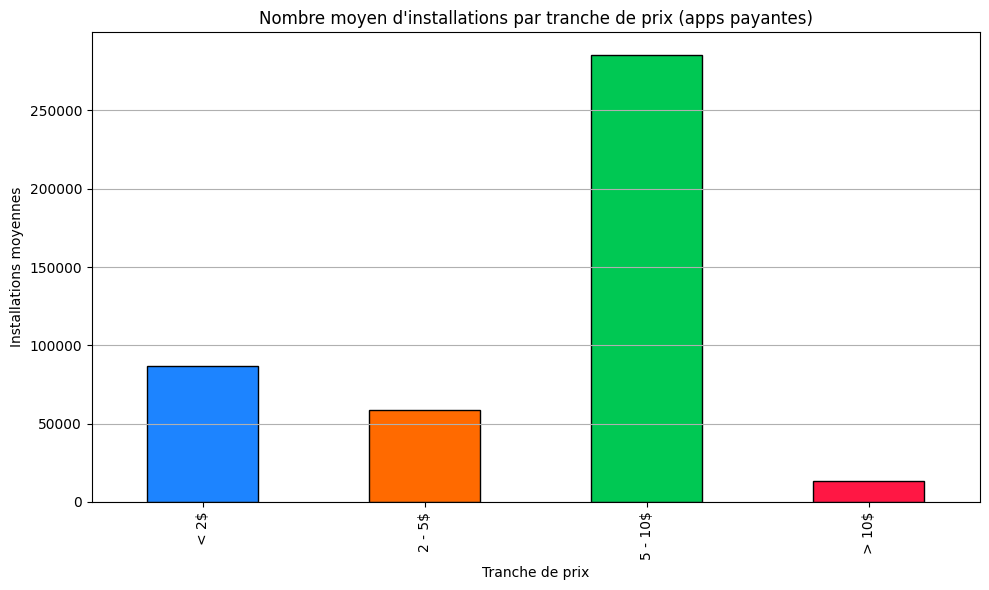

In [2]:
# tranches de prix
paid_apps = data[data["Price"] > 0]
price_bins = [0, 2, 5, 10, paid_apps["Price"].max()]
price_labels = ["< 2$", "2 - 5$", "5 - 10$", "> 10$"]
paid_apps["Price Category"] = pd.cut(paid_apps["Price"], bins=price_bins, labels=price_labels, include_lowest=True)

# nombre moyen d’installations par tranche de prix
mean_installs_per_category = paid_apps.groupby("Price Category")["Installs"].mean()

# couleurs
num_bars = len(mean_installs_per_category)
colors = google_play_colors[:num_bars]  

# diagramme 
plt.figure(figsize=(10,6))
mean_installs_per_category.plot(
    kind='bar',
    edgecolor='black',
    color=colors  
)

plt.title("Nombre moyen d'installations par tranche de prix (apps payantes)")
plt.xlabel("Tranche de prix")
plt.ylabel("Installations moyennes")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

2. Chiffre d'affaire moyen par catégorie de prix : 

/var/folders/hb/yj7h7wh17zs9x0kbfz615q9c0000gn/T/ipykernel_52821/3723559571.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paid_apps["Revenue"] = paid_apps["Price"] * paid_apps["Installs"]
/var/folders/hb/yj7h7wh17zs9x0kbfz615q9c0000gn/T/ipykernel_52821/3723559571.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_revenue_per_price_category = paid_apps.groupby("Price Category")["Revenue"].mean()


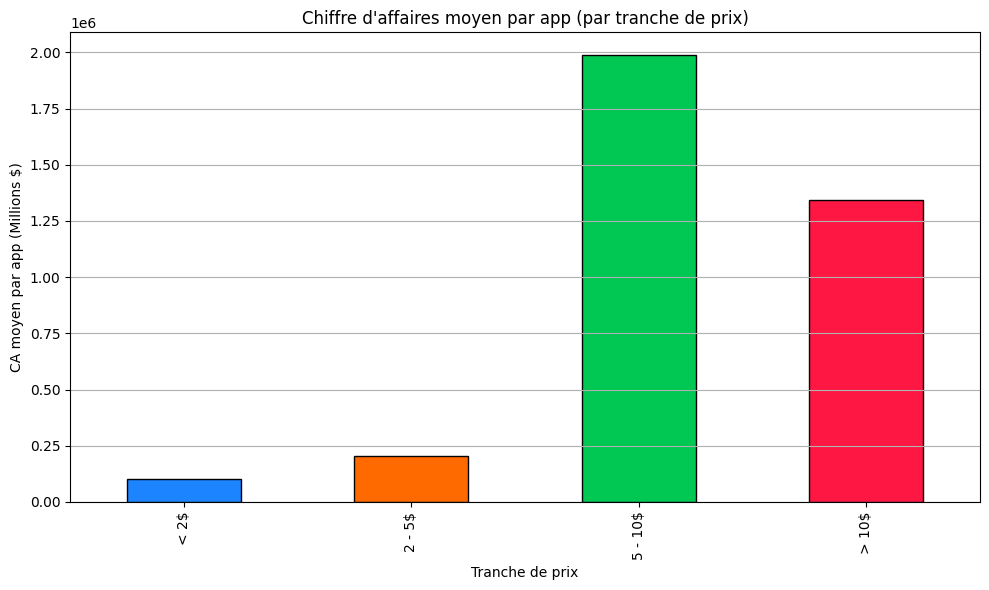

In [3]:

# revenu pour chaque app et tranche de prix
paid_apps["Revenue"] = paid_apps["Price"] * paid_apps["Installs"]
mean_revenue_per_price_category = paid_apps.groupby("Price Category")["Revenue"].mean()

# diagramme en barres
num_bars = len(mean_revenue_per_price_category)
colors = google_play_colors[:num_bars]
plt.figure(figsize=(10,6))
mean_revenue_per_price_category.plot(kind='bar', edgecolor='black', color=colors)
plt.title("Chiffre d'affaires moyen par app (par tranche de prix)")
plt.xlabel("Tranche de prix")
plt.ylabel("CA moyen par app (Millions $)")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

3. Taille de l'app et son prix de vente : 

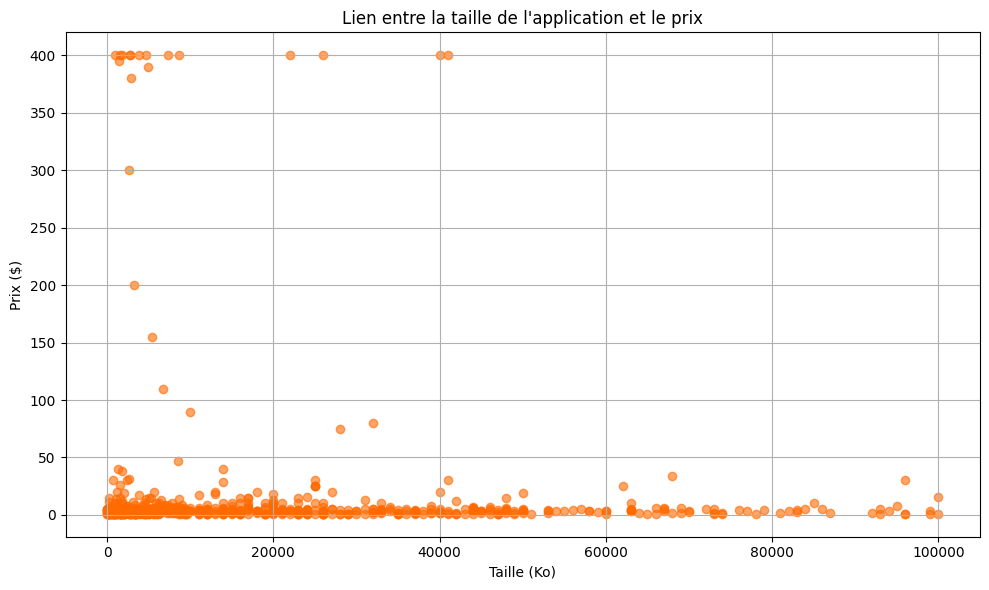

In [4]:
#  apps payantes avec taille >0 
paid_apps_with_size = paid_apps[paid_apps["Size"].notnull()]

# Scatter plot 
plt.figure(figsize=(10,6))
plt.scatter(paid_apps_with_size["Size"], paid_apps_with_size["Price"], alpha=0.6, color='#FF6A00')
plt.title("Lien entre la taille de l'application et le prix")
plt.xlabel("Taille (Ko)")
plt.ylabel("Prix ($)")
plt.grid(True)
plt.tight_layout()
plt.show()